<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Major League Baseball Data](https://github.com/Query-farm/vgi-mlb)

MLB standings and batting, pitching, and fielding statistics as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-mlb/blob/main/notebooks/03_keep_player_team_and_career_scopes_separate.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-mlb/blob/main/notebooks/README.md)


## Keep player, team and career scopes separate

How can a traded player have one season total, two team contributions and a much larger career denominator? Reconcile Josh Naylor's batting and Jhoan Duran's pitching across six real worker calls, then change only the displayed aggregation scope.

**Real public MLB responses, recorded independently on 2026-11-15 UTC.**
The default replays unchanged response bodies through the real released worker.
These are historical observations, not a synthetic scenario or an atomic live
snapshot. The [provenance manifest](recordings/provenance.json) records exact URLs,
request parameters, acquisition times and hashes. All joins and choices remain visible SQL.

### Choose one local rule

**RATE_SCOPE** is "team" or "season". Both modes retrieve the same six public responses. The default keeps each 2025 club contribution separate; the experiment pools each player's two teams by summing numerators and denominators before computing a rate.

In [1]:
DATA_MODE = "replay"
RATE_SCOPE = "team"  # Experiment: "season"

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.51":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.51"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("mlb")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from mlb_examples import MLBExample

if RATE_SCOPE not in {"team", "season"}:
    raise ValueError("RATE_SCOPE must be team or season")
source = MLBExample(DATA_MODE, "trades")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public MLB responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public MLB responses · independent endpoint reads"
) + " · worker v0.4.1"

### Attach the released worker

The public tag owns dependencies in an isolated Python 3.13 worker environment.
Shared base tooling leaves the kernel intact and starts UTC with an empty temporary
SQL-secret store and persistence disabled. The replay helper redirects the MLB root
to loopback, verifies response hashes and rejects requests outside this scenario.
Live mode clears inherited URL overrides and never falls back to replay.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mlb' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-mlb@v0.4.1 vgi-mlb');

,Success


### Request explicit statistical scopes

Stable player IDs select Josh Naylor (647304) and Jhoan Duran (661395). Career calls return regular-season totals available **at acquisition**, with no season or team attribution. Team-split calls select **2025** and retain each club. Game logs select the same regular season, preserving dates and the team actually represented in each appearance.

All six calls are materialized once. They are independent public reads, not one atomic transaction. Career totals can include seasons after 2025; they must not be substituted for a 2025 denominator. The worker filters the upstream year-by-year response to the requested season and team-bearing rows.

In [5]:
%%sql
CREATE TABLE naylor_career AS SELECT * FROM mlb.main.batting_career(647304,game_type:='R');
CREATE TABLE naylor_teams AS SELECT * FROM mlb.main.batting_team_splits(647304,2025,game_type:='R');
CREATE TABLE naylor_games AS SELECT * FROM mlb.main.batting_game_log(647304,season:=2025,game_type:='R');
CREATE TABLE duran_career AS SELECT * FROM mlb.main.pitching_career(661395,game_type:='R');
CREATE TABLE duran_teams AS SELECT * FROM mlb.main.pitching_team_splits(661395,2025,game_type:='R');
CREATE TABLE duran_games AS SELECT * FROM mlb.main.pitching_game_log(661395,season:=2025,game_type:='R');

,Count


In [6]:
%%sql career_context <<
SELECT 'Josh Naylor' AS player,'Hits / at-bats' AS quantity,
 c.hits AS career_numerator,c.at_bats AS career_denominator,
 s.hits AS season_numerator,s.at_bats AS season_denominator,
 1.0*c.hits/nullif(c.at_bats,0) AS career_rate,
 1.0*s.hits/nullif(s.at_bats,0) AS season_rate,
 100.0*s.at_bats/nullif(c.at_bats,0) AS season_share_of_career_exposure
FROM naylor_career c CROSS JOIN (SELECT sum(hits) AS hits,sum(at_bats) AS at_bats FROM naylor_teams) s
UNION ALL
SELECT 'Jhoan Duran','Earned runs × 27 / outs',c.earned_runs,c.outs,s.earned_runs,s.outs,
 27.0*c.earned_runs/nullif(c.outs,0),27.0*s.earned_runs/nullif(s.outs,0),100.0*s.outs/nullif(c.outs,0)
FROM duran_career c CROSS JOIN (SELECT sum(earned_runs) AS earned_runs,sum(outs) AS outs FROM duran_teams) s
ORDER BY player DESC;

In [7]:
display(career_context)
a, b = career_context.iloc[0], career_context.iloc[1]
prose(
    f"Naylor's acquired career row contains **{int(a.career_numerator)} hits / {int(a.career_denominator)} at-bats**, while his two 2025 clubs sum to **{int(a.season_numerator)} / {int(a.season_denominator)}**. The 2025 at-bats are **{a.season_share_of_career_exposure:.1f}%** of that career exposure. Duran's acquired career row has **{int(b.career_numerator)} earned runs / {int(b.career_denominator)} outs**, versus **{int(b.season_numerator)} / {int(b.season_denominator)}** in 2025 (**{b.season_share_of_career_exposure:.1f}%** of career outs). These are different time scopes, not additional 2025 team contributions."
)

,player,quantity,career_numerator,career_denominator,season_numerator,season_denominator,career_rate,season_rate,season_share_of_career_exposure
0,Josh Naylor,Hits / at-bats,853,3187,160.0,543.0,0.267650,0.294659,17.037967
1,Jhoan Duran,Earned runs × 27 / outs,81,941,16.0,210.0,2.324123,2.057143,22.316684


Naylor's acquired career row contains **853 hits / 3187 at-bats**, while his two 2025 clubs sum to **160 / 543**. The 2025 at-bats are **17.0%** of that career exposure. Duran's acquired career row has **81 earned runs / 941 outs**, versus **16 / 210** in 2025 (**22.3%** of career outs). These are different time scopes, not additional 2025 team contributions.

### Reconcile game rows before calculating club rates

Sum each game log by stable team ID and compare with the team-season report. Game counts, hits, at-bats, home runs, outs, earned runs and strikeouts should reconcile at their appropriate grain. The game-log pitching ERA column may be a reported running summary; **do not average it**. Derive ERA from summed earned runs and integer outs instead.

The chart shows exposures twice: once from aggregated game rows and once from the team-season response. Agreement is a consistency check, not independent evidence that doubles the sample size. The batting and pitching axes use different units.

In [8]:
%%sql
CREATE TABLE batting_check AS
SELECT t.team_id,t.team_name,t.team_abbreviation,t.hits,t.at_bats,t.home_runs,t.games_played,
 g.games,g.hits AS log_hits,g.at_bats AS log_at_bats,g.home_runs AS log_home_runs,
 g.first_game,g.last_game
FROM naylor_teams t FULL JOIN (
 SELECT team_id,count(*) AS games,sum(hits) AS hits,sum(at_bats) AS at_bats,sum(home_runs) AS home_runs,
 min(game_date) AS first_game,max(game_date) AS last_game
 FROM naylor_games GROUP BY team_id
) g USING(team_id);
CREATE TABLE pitching_check AS
SELECT t.team_id,t.team_name,t.team_abbreviation,t.outs,t.earned_runs,t.strikeouts,t.games_pitched,
 g.games,g.outs AS log_outs,g.earned_runs AS log_earned_runs,g.strikeouts AS log_strikeouts,
 g.first_game,g.last_game
FROM duran_teams t FULL JOIN (
 SELECT team_id,count(*) AS games,sum(outs) AS outs,sum(earned_runs) AS earned_runs,sum(strikeouts) AS strikeouts,
 min(game_date) AS first_game,max(game_date) AS last_game
 FROM duran_games GROUP BY team_id
) g USING(team_id);

,Count


In [9]:
%%sql exposures <<
SELECT 'Josh Naylor' AS player,team_id,team_name,team_abbreviation,'At-bats' AS unit,
 at_bats AS team_report,log_at_bats AS game_log,games,first_game,last_game
FROM batting_check
UNION ALL
SELECT 'Jhoan Duran',team_id,team_name,team_abbreviation,'Recorded outs',outs,log_outs,games,first_game,last_game
FROM pitching_check ORDER BY player,first_game;

,player,team_id,team_name,team_abbreviation,unit,team_report,game_log,games,first_game,last_game
0,Jhoan Duran,142,Minnesota Twins,MIN,Recorded outs,148,148.0,49,2025-03-29,2025-07-28
1,Jhoan Duran,143,Philadelphia Phillies,PHI,Recorded outs,62,62.0,23,2025-08-01,2025-09-26
2,Josh Naylor,109,Arizona Diamondbacks,AZ,At-bats,349,349.0,93,2025-03-27,2025-07-23
3,Josh Naylor,136,Seattle Mariners,SEA,At-bats,194,194.0,54,2025-07-25,2025-09-26


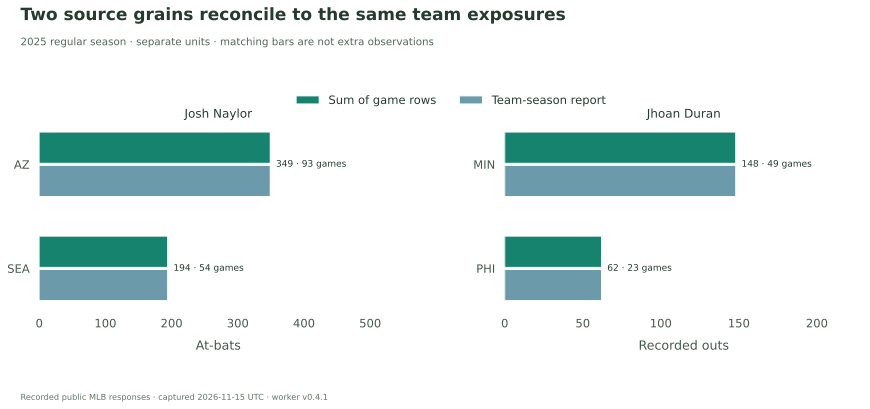

The logs contain **147 Naylor games** and **72 Duran appearances**. All four team denominators match the team-season reports; displayed date spans retain the historical club context.

In [10]:
display(exposures)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, player in zip(axes, ["Josh Naylor", "Jhoan Duran"]):
    p = exposures[exposures.player == player].sort_values("first_game")
    y = np.arange(len(p))
    ax.barh(y - 0.16, p.game_log, height=0.3, color="#16836e", label="Sum of game rows")
    ax.barh(y + 0.16, p.team_report, height=0.3, color="#6b9aaa", label="Team-season report")
    for i, row in enumerate(p.itertuples()):
        ax.text(
            row.team_report + max(p.team_report) * 0.025,
            i,
            f"{row.team_report} · {row.games} games",
            va="center",
            fontsize=9,
        )
    ax.set_yticks(y, p.team_abbreviation)
    ax.invert_yaxis()
    ax.set_xlim(0, float(p.team_report.max()) * 1.55)
    ax.set_xlabel(p.unit.iloc[0])
    ax.set_title(player, fontsize=12)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.53, 0.79), ncol=2, frameon=False)
finish(
    fig,
    title="Two source grains reconcile to the same team exposures",
    subtitle="2025 regular season · separate units · matching bars are not extra observations",
    source=SOURCE,
    name="team-exposure-audit",
)
prose(
    f"The logs contain **{int(exposures[exposures.player == 'Josh Naylor'].games.sum())} Naylor games** and **{int(exposures[exposures.player == 'Jhoan Duran'].games.sum())} Duran appearances**. All four team denominators match the team-season reports; displayed date spans retain the historical club context."
)

### Choose the displayed aggregation, not a new source

For team scope, each club retains its numerator and exposure. For season scope, sum those counts first. The pooled rate equals an **exposure-weighted** average of team rates, not necessarily their simple mean. Career reference lines remain separately labeled because their time window differs.

These two players illustrate aggregation and attribution. Differences between clubs do not establish a trade effect: timing, opponents, workload and other conditions differ, and no causal or predictive model is fitted.

In [11]:
%%sql selected_rates <<
WITH raw AS (
 SELECT 'Josh Naylor' AS player,team_abbreviation AS club,hits AS numerator,at_bats AS exposure,1.0 AS factor FROM naylor_teams
 UNION ALL SELECT 'Jhoan Duran',team_abbreviation,earned_runs,outs,27.0 FROM duran_teams
)
SELECT player,CASE WHEN '{{RATE_SCOPE}}'='team' THEN club ELSE 'Whole 2025 season' END AS displayed_scope,
 sum(numerator) AS numerator,sum(exposure) AS exposure,max(factor) AS factor,
 max(factor)*sum(numerator)/nullif(sum(exposure),0) AS rate
FROM raw GROUP BY player,displayed_scope ORDER BY player,displayed_scope;

,player,displayed_scope,numerator,exposure,factor,rate
0,Jhoan Duran,MIN,11.0,148.0,27.0,2.006757
1,Jhoan Duran,PHI,5.0,62.0,27.0,2.177419
2,Josh Naylor,AZ,102.0,349.0,1.0,0.292264
3,Josh Naylor,SEA,58.0,194.0,1.0,0.298969


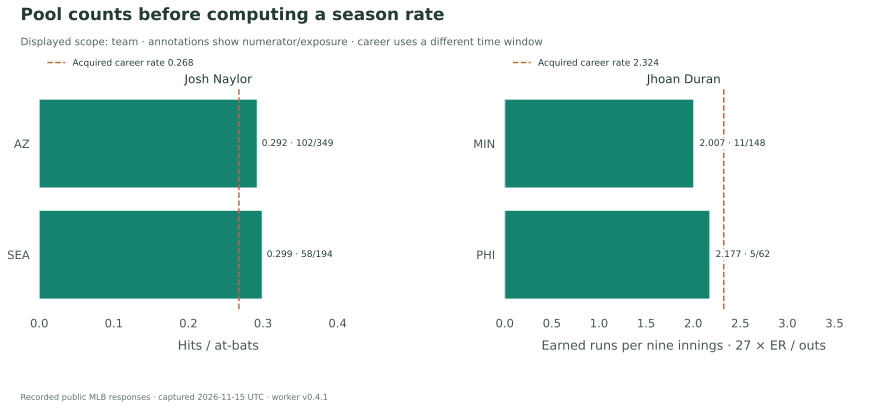

The **team** view has **4 rate rows**. Their underlying team numerators and exposures are unchanged. The career references remain **0.268 hits per at-bat** and **2.324 earned runs per nine**, using their own larger denominators.

In [12]:
display(selected_rates)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, player in zip(axes, ["Josh Naylor", "Jhoan Duran"]):
    p = selected_rates[selected_rates.player == player]
    career = career_context[career_context.player == player].iloc[0]
    y = np.arange(len(p))
    ax.barh(y, p.rate, color="#16836e")
    for i, row in enumerate(p.itertuples()):
        ax.text(
            row.rate + 0.006 if player == "Josh Naylor" else row.rate + 0.06,
            i,
            f"{row.rate:.3f} · {int(row.numerator)}/{int(row.exposure)}",
            va="center",
            fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
            zorder=5,
        )
    ax.axvline(
        career.career_rate,
        color="#b66d3e",
        linestyle="--",
        linewidth=1.5,
        label=f"Acquired career rate {career.career_rate:.3f}",
    )
    ax.set_yticks(y, p.displayed_scope)
    ax.invert_yaxis()
    ax.set_xlim(0, 0.48 if player == "Josh Naylor" else 3.8)
    ax.set_xlabel(
        "Hits / at-bats" if player == "Josh Naylor" else "Earned runs per nine innings · 27 × ER / outs"
    )
    ax.set_title(player, fontsize=12)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.06), fontsize=9, frameon=False)
finish(
    fig,
    title="Pool counts before computing a season rate",
    subtitle=f"Displayed scope: {RATE_SCOPE} · annotations show numerator/exposure · career uses a different time window",
    source=SOURCE,
    name=f"scope-rates-{RATE_SCOPE}",
)
prose(
    f"The **{RATE_SCOPE}** view has **{len(selected_rates)} rate rows**. Their underlying team numerators and exposures are unchanged. The career references remain **{career_context.career_rate.iloc[0]:.3f} hits per at-bat** and **{career_context.career_rate.iloc[1]:.3f} earned runs per nine**, using their own larger denominators."
)

In [13]:
%%sql checks <<
SELECT 'one regular-season career row per player' AS check_name,
 (SELECT count(*)=1 AND bool_and(player_id=647304 AND game_type='R' AND season IS NULL AND team_id IS NULL) FROM naylor_career)
 AND (SELECT count(*)=1 AND bool_and(player_id=661395 AND game_type='R' AND season IS NULL AND team_id IS NULL) FROM duran_career) AS passed
UNION ALL SELECT 'batting team keys unique and scoped',count(*)=count(DISTINCT team_id) AND count(*)>0 AND bool_and(season=2025 AND player_id=647304 AND game_type='R') FROM naylor_teams
UNION ALL SELECT 'pitching team keys unique and scoped',count(*)=count(DISTINCT team_id) AND count(*)>0 AND bool_and(season=2025 AND player_id=661395 AND game_type='R') FROM duran_teams
UNION ALL SELECT 'batting game IDs unique and scoped',count(*)=count(DISTINCT game_pk) AND count(*)>0 AND bool_and(season=2025 AND player_id=647304 AND game_type='R') FROM naylor_games
UNION ALL SELECT 'pitching game IDs unique and scoped',count(*)=count(DISTINCT game_pk) AND count(*)>0 AND bool_and(season=2025 AND player_id=661395 AND game_type='R') FROM duran_games
UNION ALL SELECT 'batting counts reconcile across source grains',bool_and(coalesce(hits=log_hits AND at_bats=log_at_bats AND home_runs=log_home_runs AND games_played=games,false)) AND count(*)=(SELECT count(*) FROM naylor_teams) FROM batting_check
UNION ALL SELECT 'pitching counts reconcile across source grains',bool_and(coalesce(outs=log_outs AND earned_runs=log_earned_runs AND strikeouts=log_strikeouts AND games_pitched=games,false)) AND count(*)=(SELECT count(*) FROM duran_teams) FROM pitching_check
UNION ALL SELECT 'batting career contains at least the selected season',(SELECT hits FROM naylor_career)>=(SELECT sum(hits) FROM naylor_teams) AND (SELECT at_bats FROM naylor_career)>=(SELECT sum(at_bats) FROM naylor_teams)
UNION ALL SELECT 'pitching career contains at least the selected season',(SELECT earned_runs FROM duran_career)>=(SELECT sum(earned_runs) FROM duran_teams) AND (SELECT outs FROM duran_career)>=(SELECT sum(outs) FROM duran_teams)
UNION ALL SELECT 'batting weighted rate equals pooled counts',abs(sum(1.0*hits/nullif(at_bats,0)*at_bats)/sum(at_bats)-1.0*sum(hits)/sum(at_bats))<1e-12 FROM naylor_teams
UNION ALL SELECT 'pitching weighted rate equals pooled counts',abs(sum(27.0*earned_runs/nullif(outs,0)*outs)/sum(outs)-27.0*sum(earned_runs)/sum(outs))<1e-12 FROM duran_teams
UNION ALL SELECT 'batting rate agrees with report rounding',count(*)=0 FROM naylor_teams WHERE abs(1.0*hits/nullif(at_bats,0)-CAST(batting_average AS DOUBLE))>.000500001
UNION ALL SELECT 'pitching rate agrees with report rounding',count(*)=0 FROM duran_teams WHERE abs(27.0*earned_runs/nullif(outs,0)-CAST(era AS DOUBLE))>.005000001;

In [14]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "parameters": {"DATA_MODE": DATA_MODE, "RATE_SCOPE": RATE_SCOPE},
            "career_context": career_context.to_dict("records"),
            "exposures": exposures.to_dict("records"),
            "selected_rates": selected_rates.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,one regular-season career row per player,True
1,batting team keys unique and scoped,True
2,pitching team keys unique and scoped,True
3,batting game IDs unique and scoped,True
4,pitching game IDs unique and scoped,True
5,batting counts reconcile across source grains,True
6,pitching counts reconcile across source grains,True
7,batting career contains at least the selected ...,True
8,pitching career contains at least the selected...,True
9,batting weighted rate equals pooled counts,True


**All 13 SQL checks passed.** Exactly 6 recorded responses requested once each; no unexpected requests.

4421

### Change one thing

Change **RATE_SCOPE from "team" to "season"**. Four club rate rows collapse to two player-season rows, computed from pooled counts. The full game logs, source reconciliation chart, career values and request audit must remain unchanged. Compare each pooled rate with its exposure-weighted team rates; never average the two clubs without weighting. Restore "team" for the saved default.

In [15]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-mlb](https://github.com/Query-farm/vgi-mlb)